# How much better is the best model? → `figure_model_comparison.pdf`

Figure 4f. **How much better is the best model?** — a difference in expected log predictive
density, in nats per trial, with a 95% confidence interval of the mean **across neurons**.

Across neurons, and what that does not cover. The whisker treats each neuron as one independent
observation, whatever session it came from, so it answers *how precisely is the mean over these
neurons pinned down*. It does not answer *would another session look like this*: simultaneously
recorded neurons share trials, share a stimulus sequence and have correlated receptive fields, so
the session is the unit that is plausibly independent, and a neuron-level interval is narrower
than a session-level one by `inflation`. The cluster-robust error across sessions and the
session-level bootstrap are computed here too and printed beside it, so the size of that gap is
visible rather than asserted.

Nothing is refit: every number comes from the cached `dtest_ll_mean` (the paired per-split
held-out ΔLL against a constant fit to the same trials) times each neuron's trial count.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import common
common.set_style()
import elpd_lib as el
import models_lib as ml

MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    'basis_function',
    'future_field',
)
LABELS = ml.MODEL_LABELS_SHORT

# The accents shared with figure_ks_stats.ipynb, so the panels of figure 4 read together.
ACCENT, ACCENT_MODEL = '#c1272d', 'future_field'
SECOND_ACCENT, SECOND_ACCENT_MODEL = '#8e3b6b', 'basis_function'
GRAY_LIGHT, GRAY_DARK = 0.82, 0.2


def model_colors(models=MODELS):
    accents = {ACCENT_MODEL: ACCENT, SECOND_ACCENT_MODEL: SECOND_ACCENT}
    n_grey = sum(m not in accents for m in models)
    greys = iter(np.linspace(GRAY_LIGHT, GRAY_DARK, max(n_grey, 1)))
    return {m: (accents[m] if m in accents else str(next(greys))) for m in models}


COLORS = model_colors()
SUBJECTS = ('Perle', 'Elgar')
TITLES = {'Perle': 'Monkey P', 'Elgar': 'Monkey E'}

# Styling matched to the other figure-4 panels, so they can be read side by side without
# discounting a difference in how they are drawn.
FIGSIZE = (5.5, 3.1)
OUTPUT = 'figure_model_comparison.pdf'
XTICK_ROTATION = -50   # degrees; 0 is horizontal
XTICK_HA = 'left'      # 'left' evenly spaces the labels' LEFT ends under their ticks ...
XTICK_SHIFT_IN = -0.2  # ... and puts the block right of them, which this shifts back

# Horizontal space between the two panels. WSPACE is constrained layout's MINIMUM gap and it
# bottoms out well short of zero here — the right panel has its own y tick labels, since the
# animals do not share a scale, and those set the floor (0.17 -> 0 closes the gap only from
# 0.213 to 0.139 of the figure width). COLUMN_SHIFT_IN slides the right panel left, in INCHES,
# after the layout has settled, which is the only way past that floor. Same knob as
# ../figure_3/model_comparison.
WSPACE = 0.08
COLUMN_SHIFT_IN = 0.35

POINT_SIZE = 10          # diameter of the summary marker, in points
ERR_LINEWIDTH = 1.2     # its error bar
ERR_CAPSIZE = 4

# The y axis is a likelihood, not a log-likelihood: the reference sits at 1 and 0.91 means
# each held-out trial is 9% less likely under that model.
YLABEL = 'Relative likelihood'
N_BOOT = 2000          # session-level bootstrap draws


## The comparison

`delta_per_unit` is the total held-out log-likelihood difference over all neurons and trials,
divided by the total trial count. A value of −0.05 means each trial is predicted 0.05 nats worse
under that model than under the reference.

In [2]:
summary = common.selected_fits(MODELS)

tables = {}
for s_ in SUBJECTS:
    t = el.elpd_table(summary, MODELS, subject=s_, n_boot=N_BOOT)
    tables[TITLES[s_]] = t
    print(f'── {TITLES[s_]} — reference: {t.attrs["reference"]} '
          f'({t["n_neurons"].iat[0]} neurons, {t["n_clusters"].iat[0]} sessions)')
    display(t[['model', 'delta_per_unit', 'neuron_ci_lo_per_unit', 'neuron_ci_hi_per_unit',
               'se_cluster_per_unit', 'lo_per_unit', 'hi_per_unit',
               'se_neuron_per_unit', 'inflation']].round(5))

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
  restricted to 5 models (weighted_average, normalization, inhibition, basis_function, future_field); best_model recomputed within them
  dropped: relational_bias
1339 of 1339 neurons enter the figure (100%)
── Monkey P — reference: future_field (998 neurons, 10 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.09480,-0.10946,-0.08013,0.03086,-0.15593,-0.04574,0.00747,4.13038
1,normalization,-0.07537,-0.08802,-0.06271,0.02633,-0.12684,-0.03339,0.00645,4.08303
2,inhibition,-0.04569,-0.05955,-0.03182,0.01359,-0.07394,-0.02400,0.00707,1.92372
3,basis_function,0.00003,-0.00187,0.00193,0.00115,-0.00230,0.00190,0.00097,1.18137
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


── Monkey E — reference: future_field (341 neurons, 12 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.03854,-0.04733,-0.02975,0.00901,-0.05636,-0.02234,0.00447,2.01457
1,normalization,-0.02900,-0.03634,-0.02166,0.00684,-0.04206,-0.01696,0.00373,1.83309
2,inhibition,-0.01748,-0.02737,-0.00760,0.00706,-0.03141,-0.00521,0.00503,1.40515
3,basis_function,-0.00159,-0.00359,0.00042,0.00077,-0.00303,-0.00013,0.00102,0.75856
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


## The figure

Drawn in the style of figure 4's other panels — same model order, same colours, same rotated
labels — so they can be read side by side.

**What the point and its whisker are.** The point is the *population* estimate — the total
held-out log-likelihood difference over all neurons and trials, divided by the total trial count
— and the whisker is a 95% confidence interval of that mean **across neurons**, with the neurons
treated as independent regardless of session. It is an interval on the population estimate, not
on the spread across neurons, which at ~1000 neurons is very much wider. Because it ignores the session
structure it is narrower than the cluster-robust interval by `inflation` in the table above. The dashed line at 1
is the reference model, and each point's distance from it is that model's shortfall.

The axis is a **likelihood** rather than a log-likelihood: the reference sits at 1, and 0.91 means
each held-out trial is 9% less likely under that model. Exponentiating
is monotone, so the interval endpoints map exactly — it is the same interval on a multiplicative
scale, and the asymmetry it acquires is real rather than an artefact. Note that `exp` of a mean
log-likelihood is a *geometric* mean of per-trial likelihood ratios: that is the right summary
here, since the whole dataset's likelihood ratio is `exp` of the summed log ratio, but it is not
the arithmetic mean of the ratios and should not be described as one.

**The constant-rate model** — a neuron that ignores the stimulus entirely — is *printed below
rather than drawn*: on this axis it sits far below every model shown, and a line there would
flatten all five against the top. Every likelihood here is already measured against it, so it is
the origin of the scale, and it is what tells you whether the gaps between models are large or small. They are small: the *worst* model
recovers about three-quarters of the distance from a constant rate to the best one, so this
comparison is an argument over the last quarter.

The panels do **not** share a y axis: the two animals differ several-fold in the size of these
differences, and a shared scale would make the smaller one unreadable to make a point the numbers
already make. The reference model is the future-field model in both panels; it is named in the table above.

saved figure_model_comparison.pdf


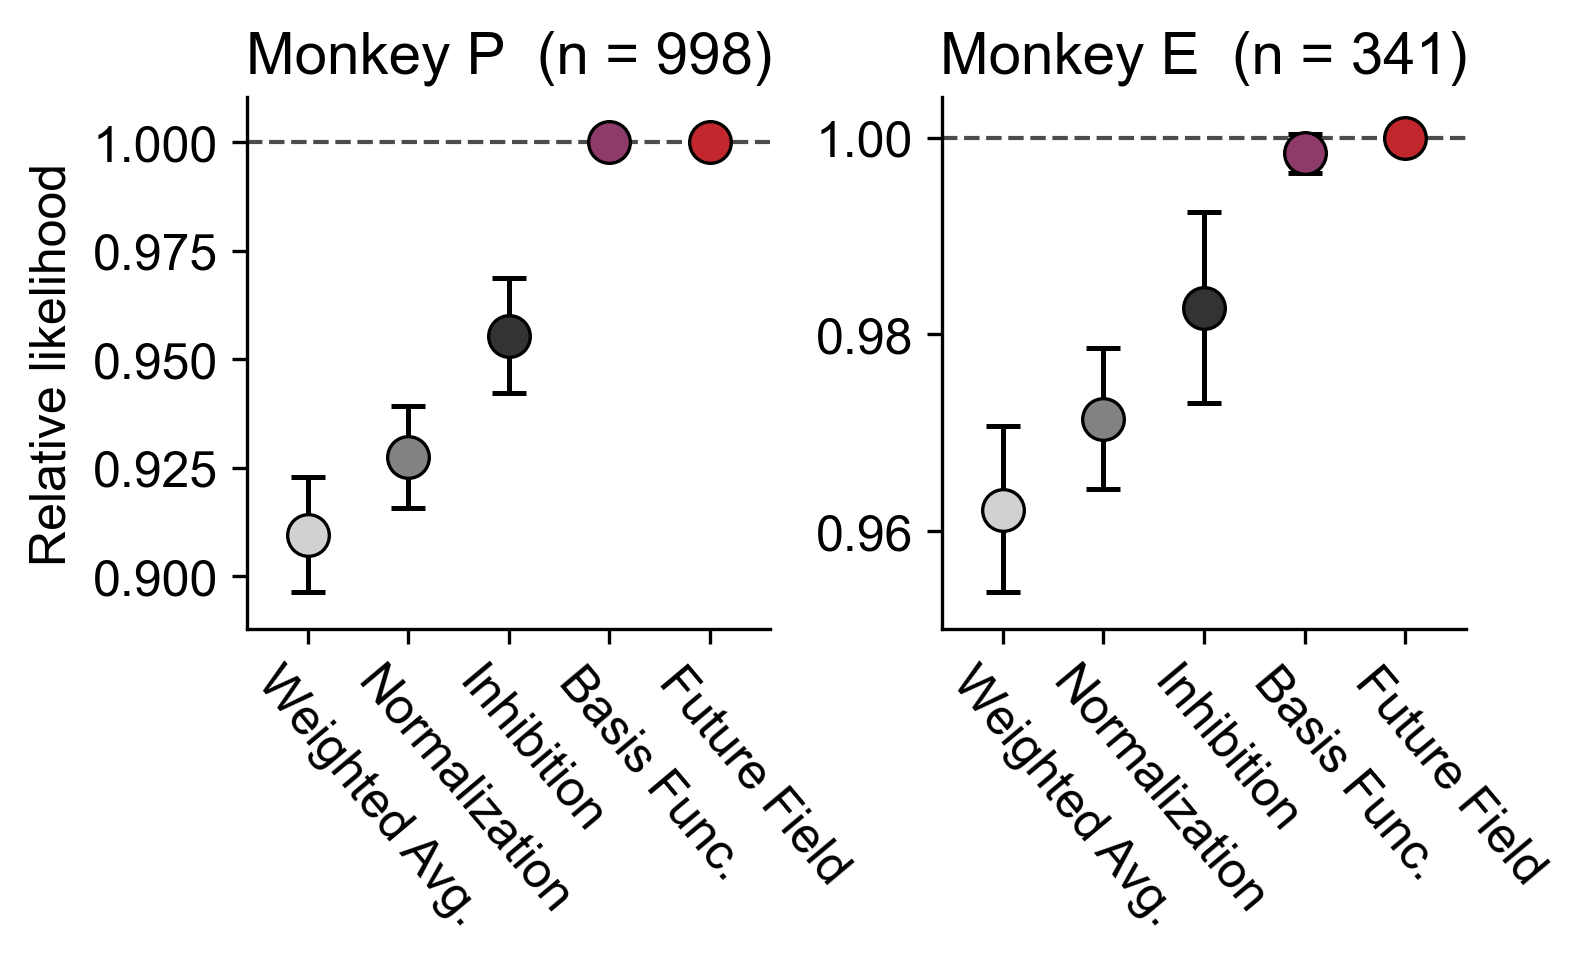

In [3]:
pop = summary.drop_duplicates(['subject', 'session', 'unit'])
n_by_subject = {TITLES[s_]: int((pop['subject'] == s_).sum()) for s_ in SUBJECTS}

fig = el.plot_elpd(tables, COLORS, figsize=FIGSIZE, labels=LABELS,
                   xtick_rotation=XTICK_ROTATION, xtick_ha=XTICK_HA,
                   shift_in=XTICK_SHIFT_IN, n_by_subject=n_by_subject,
                   wspace=WSPACE, column_shift_in=COLUMN_SHIFT_IN, ylabel=YLABEL,
                   point_size=POINT_SIZE, err_linewidth=ERR_LINEWIDTH,
                   err_capsize=ERR_CAPSIZE)
common.save(fig, OUTPUT)
plt.show()

## The constant-rate model

Every likelihood here is already measured against a neuron that **ignores the stimulus**, so
that model is the origin of the whole scale. It is printed rather than drawn: on this axis it
sits far below every model shown, and a line there would flatten all five against the top.

What it gives is the size of the thing being argued over. The models differ from each other by a
few per cent per trial; they differ from a constant rate by very much more, and the *worst* of
them already recovers most of that distance.

In [4]:
for s_ in SUBJECTS:
    t = tables[TITLES[s_]]
    _, units, c0 = el.per_neuron_delta(summary, MODELS, t.attrs['reference'], subject=s_)
    worst = t['delta_per_unit'].min()
    print(f'{TITLES[s_]}  (reference {t.attrs["reference"]})')
    print(f'    constant rate: {c0:+.4f} nats/trial  ->  relative likelihood '
          f'{np.exp(c0):.4f} per trial, {np.exp(c0 * units["n_2obj"].mean()):.3g} per neuron')
    print(f'    worst model:   {worst:+.4f} nats/trial  ->  {np.exp(worst):.4f} per trial, '
          f'i.e. {100 * (1 - worst / c0):.0f}% of the way from a constant rate to the best')

Monkey P  (reference future_field)
    constant rate: -0.3807 nats/trial  ->  relative likelihood 0.6834 per trial, 8.22e-131 per neuron
    worst model:   -0.0948 nats/trial  ->  0.9096 per trial, i.e. 75% of the way from a constant rate to the best
Monkey E  (reference future_field)
    constant rate: -0.1726 nats/trial  ->  relative likelihood 0.8415 per trial, 6.88e-62 per neuron
    worst model:   -0.0385 nats/trial  ->  0.9622 per trial, i.e. 78% of the way from a constant rate to the best
